In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 1. Zip dosyasını Drive'dan hızlı yerel diske kopyala
!cp /content/drive/MyDrive/Mtu_Proje_pazari/Araba_Fiyat_Tahmin.zip /content/

# 2. Yerel diskte 'dataset' adında bir klasör oluştur
!mkdir /content/dataset

# 3. Zipi bu klasörün içine çıkart
# DİKKAT: -q (quiet) parametresi çok önemlidir!
# Yazmazsan tarayıcın 10.000 dosya ismini ekrana basmaya çalışırken çöker.
!unzip -q /content/Araba_Fiyat_Tahmin.zip -d /content/dataset/

# 4. İşlem bitince gereksiz yer kaplayan ana zip dosyasını yerel diskten sil
!rm /content/Araba_Fiyat_Tahmin.zip

In [ ]:
import os
import glob
import pandas as pd
import html

def olustur_tabular_veriseti(ana_klasor, cikti_dosyasi):
    print("Metin dosyaları taranıyor...")

    # Tüm ilan_bilgileri.txt dosyalarını bul
    txt_dosyalari = glob.glob(os.path.join(ana_klasor, "**", "ilan_bilgileri.txt"), recursive=True)

    if not txt_dosyalari:
        print("Hata: Hiç txt dosyası bulunamadı. Lütfen klasör yolunu kontrol et.")
        return

    veriler = []

    for txt_yolu in txt_dosyalari:
        satir_verisi = {}

        # 4. Kolon için: Arabanın görsellerinin bulunduğu klasörün tam yolu
        klasor_yolu = os.path.dirname(txt_yolu)
        satir_verisi['Görsel Klasör Yolu'] = klasor_yolu

        # Txt dosyasını oku ve parçala
        try:
            with open(txt_yolu, 'r', encoding='utf-8') as f:
                for satir in f:
                    if ':' in satir:
                        anahtar, deger = satir.split(':', 1)
                        anahtar = anahtar.strip()
                        # HTML karakterlerini düzelt (Örn: D&#252;z -> Düz)
                        deger = html.unescape(deger.strip())
                        satir_verisi[anahtar] = deger
            veriler.append(satir_verisi)
        except Exception as e:
            print(f"Okuma hatası ({txt_yolu}): {e}")

    # DataFrame oluştur
    df = pd.DataFrame(veriler)

    # İstediğin sütun sıralamasını belirle
    istenen_sira = [
        'İlan No',
        'Marka',
        'Model',
        'Görsel Klasör Yolu',
        'Seri',
        'Yıl',
        'Kilometre',
        'Fiyat',
        'Kasa Tipi',
        'Yakıt',
        'Vites',
        'Motor Hacmi'
    ]

    # Eksik sütun varsa boş olarak ekle (kodun çökmemesi için)
    for sutun in istenen_sira:
        if sutun not in df.columns:
            df[sutun] = None

    # Beklenmeyen ekstra bilgiler (açıklama vb.) gelmişse onları da en sona ekle
    diger_sutunlar = [col for col in df.columns if col not in istenen_sira]
    df = df[istenen_sira + diger_sutunlar]

    # CSV olarak kaydet (utf-8-sig ile Excel'de Türkçe karakterler bozulmaz)
    df.to_csv(cikti_dosyasi, index=False, encoding='utf-8-sig')

    print(f"\n[BAŞARILI] Toplam {len(df)} ilanın verisi '{cikti_dosyasi}' dosyasına kaydedildi!")
    print(df.head(3)) # İlk 3 satırı ekranda göster

if __name__ == "__main__":
    # Ham verilerin bulunduğu ana dizin
    VERI_KLASORU = "/content/dataset"
    # Çıktı alınacak CSV dosyasının adı ve yolu
    CSV_CIKTISI = "/content/araba_fiyat_tahmin_veriseti.csv"

    olustur_tabular_veriseti(VERI_KLASORU, CSV_CIKTISI)

Metin dosyaları taranıyor...

[BAŞARILI] Toplam 7851 ilanın verisi '/content/araba_fiyat_tahmin_veriseti.csv' dosyasına kaydedildi!
    İlan No  Marka                               Model  \
0  38993796  Honda  Honda Civic 1.6i VTEC Eco Elegance   
1  38613388  Honda     Honda Civic 1.6i VTEC Executive   
2  38395641  Honda            Honda Civic 1.6i VTEC ES   

                                  Görsel Klasör Yolu   Seri   Yıl   Kilometre  \
0  /content/dataset/Araba_Fiyat_Tahmin/honda/ilan...  Civic  2021   92.000 km   
1  /content/dataset/Araba_Fiyat_Tahmin/honda/ilan...  Civic  2017  201.000 km   
2  /content/dataset/Araba_Fiyat_Tahmin/honda/ilan...  Civic  2002  279.000 km   

          Fiyat Kasa Tipi        Yakıt          Vites Motor Hacmi  
0  1.660.000 TL     Sedan  LPG  Benzin  Yarı Otomatik  Bulunamadı  
1  1.195.000 TL     Sedan  LPG  Benzin       Otomatik  Bulunamadı  
2    455.000 TL     Sedan  LPG  Benzin       Otomatik  Bulunamadı  


In [ ]:
# ==========================================
# 1. İMPORTLAR
# ==========================================
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from PIL import Image
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 2. HİPERPARAMETRELER
# ==========================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_SIZE = 224
BATCH_SIZE = 1 # Her satırdaki (ilana ait) 10 fotoğrafı tek bir seferde yüklemek için 1 seçiyoruz
CSV_PATH = "/content/araba_fiyat_tahmin_veriseti.csv"
FEATURES_NPY_PATH = "/content/gorsel_ozellikler.npy"
MODEL_SAVE_PATH = "/content/xgboost_fiyat_modeli.json"

# ==========================================
# 3. DATASET LOADER
# ==========================================
class CarImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        folder = self.df.iloc[idx]['Görsel Klasör Yolu']
        images = []

        # B. GÖRSEL ÖNİŞLEME: Klasördeki 10 adet fotoğrafı bul ve oku
        if pd.notna(folder) and os.path.exists(folder):
            img_files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))][:10]
            for img_name in img_files:
                try:
                    img_path = os.path.join(folder, img_name)
                    img = Image.open(img_path).convert('RGB')
                    if self.transform:
                        img = self.transform(img)
                    images.append(img)
                except Exception:
                    pass

        # Eğer klasör boşsa, modele hata verdirmemek için siyah (sıfır) bir tensör dönüyoruz
        if len(images) == 0:
            dummy = torch.zeros(3, IMG_SIZE, IMG_SIZE)
            return torch.stack([dummy])

        # 10 fotoğrafı yığın (stack) haline getiriyoruz. Boyut: (10, 3, 224, 224)
        return torch.stack(images)

# ==========================================
# 4. MODEL (A. KAFA KESME VE DONDURMA)
# ==========================================
def get_feature_extractor():
    print(f"[BİLGİ] ResNet18 Yükleniyor... (Cihaz: {DEVICE})")
    # Önceden eğitilmiş modeli indir
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    # Kafa Kesme: Sınıflandırma (Classification) katmanını etkisizleştir (Identity)
    # Artık bize 'araba' demek yerine 512 boyutlu özellik vektörü (matematiksel özet) verecek
    model.fc = nn.Identity()
    model.to(DEVICE)
    model.eval() # CNN'de eğitim yapmayacağız, sadece tahmin modunda kalacak
    return model

def tabular_veriyi_temizle(df):
    """
    XGBoost için metinsel olan Fiyat ve KM verilerini matematiğe dönüştürür.
    """
    df_clean = df.copy()

    # Fiyat Temizleme ("290.000 TL" -> 290000)
    if df_clean['Fiyat'].dtype == object:
        df_clean['Fiyat'] = df_clean['Fiyat'].astype(str).str.replace(' TL', '', regex=False)
        df_clean['Fiyat'] = df_clean['Fiyat'].str.replace('.', '', regex=False)
        df_clean['Fiyat'] = pd.to_numeric(df_clean['Fiyat'], errors='coerce')

    # Kilometre Temizleme ("273.800 km" -> 273800)
    if df_clean['Kilometre'].dtype == object:
        df_clean['Kilometre'] = df_clean['Kilometre'].astype(str).str.replace(' km', '', regex=False)
        df_clean['Kilometre'] = df_clean['Kilometre'].str.replace('.', '', regex=False)
        df_clean['Kilometre'] = pd.to_numeric(df_clean['Kilometre'], errors='coerce')

    # Fiyatı ve KM'si hatalı olan satırları at
    df_clean = df_clean.dropna(subset=['Fiyat', 'Kilometre'])

    # Eğitime girmeyecek sütunları at
    df_clean = df_clean.drop(columns=['İlan No', 'Görsel Klasör Yolu'], errors='ignore')

    # Sözel özellikleri makinenin anlayacağı 0 ve 1'lere dönüştür (One-Hot Encoding)
    kategorik_sutunlar = ['Marka', 'Seri', 'Model', 'Kasa Tipi', 'Yakıt', 'Vites', 'Motor Hacmi']
    df_clean = pd.get_dummies(df_clean, columns=kategorik_sutunlar, dummy_na=False)

    return df_clean

# ==========================================
# 8. MAIN
# ==========================================
def main():
    # 1. CSV Yükleme ve Hazırlık
    if not os.path.exists(CSV_PATH):
        print(f"HATA: {CSV_PATH} bulunamadı!")
        return

    df = pd.read_csv(CSV_PATH)

    # CNN için standart resim ön işlemleri
    transform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    dataset = CarImageDataset(df, transform=transform)
    dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)

    model = get_feature_extractor()
    all_features = []

    # ==========================================
    # 6. TQDM Bar Tanımlaması (B. Vektör Üretimi)
    # ==========================================
    print("\n[BİLGİ] Fotoğraflardan Özellik Çıkarımı (Feature Extraction) Başlıyor...")
    pbar = tqdm(dataloader, total=len(dataloader), desc="Görüntü İşleme")

    with torch.no_grad(): # Bellek tasarrufu
        for images in pbar:
            # images shape: (1, 10, 3, 224, 224). Squeeze ile (10, 3, 224, 224) yapıyoruz
            images = images.squeeze(0).to(DEVICE)

            # CNN'den geçirip özellikleri çıkar
            features = model(images) # Her fotoğraf için (10, 512)

            # C. 10 FOTOĞRAFI TEK ARAÇ KİMLİĞİNE DÖNÜŞTÜRME (MEAN POOLING)
            mean_feature = torch.mean(features, dim=0) # 10 vektörü toplayıp 10'a böl -> (512,)

            all_features.append(mean_feature.cpu().numpy())

    pbar.close()

    # Hesaplanan bu 512 boyutlu görsel vektörleri kaydet
    X_vision = np.array(all_features)
    np.save(FEATURES_NPY_PATH, X_vision)
    print(f"\n[BİLGİ] Görsel matris {FEATURES_NPY_PATH} olarak kaydedildi. Boyut: {X_vision.shape}")

    # ==========================================
    # MULTI-MODAL VERİ BİRLEŞTİRME (FUSION)
    # ==========================================
    df_clean = tabular_veriyi_temizle(df)

    y = df_clean['Fiyat'].values
    X_tabular = df_clean.drop(columns=['Fiyat']).values

    # Temizleme sırasında atılan sorunlu satırların görsel vektörlerini de atıyoruz
    valid_indices = df_clean.index
    X_vision_valid = X_vision[valid_indices]

    # Tablo özellikleri ile Görsel özellikleri tek bir matriste birleştiriyoruz (Fusion)
    X_final = np.hstack((X_tabular, X_vision_valid))
    print(f"[BİLGİ] Veriler Birleştirildi! Model eğitilecek toplam özellik (sütun) sayısı: {X_final.shape[1]}\n")

    # Eğitimi ve Testi ayırıyoruz (%80 Train, %20 Eval)
    X_train, X_eval, y_train, y_eval = train_test_split(X_final, y, test_size=0.2, random_state=42)

    # ==========================================
    # 5. TRAIN & 7. EVAL (XGBoost Fiyat Tahmin Eğitimi)
    # ==========================================
    print("==========================================")
    print("XGBoost Fiyat Tahmin Modeli Eğitimi Başlıyor")
    print("==========================================")

    # 9. Checkpoint (LOSS'a göre kontrol): early_stopping_rounds ile validasyon hatası (loss) düşmezse model durur.
    xgb_model = xgb.XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        tree_method='hist', # Colab GPU'su açıksa 'gpu_hist' yaparak hızı artırabilirsin
        early_stopping_rounds=50
    )

    eval_set = [(X_train, y_train), (X_eval, y_eval)]

    # Modeli Eğit (Train) ve Test Et (Eval)
    xgb_model.fit(
        X_train, y_train,
        eval_set=eval_set,
        verbose=100 # Her 100 iterasyonda bir LOSS yazdırır (TQDM alternatifi loglama)
    )

    # Checkpoint'i (En iyi modeli) Kaydet
    xgb_model.save_model(MODEL_SAVE_PATH)
    print(f"\n[BAŞARILI] En düşük kayba (loss) sahip model kaydedildi: {MODEL_SAVE_PATH}")

    # ==========================================
    # 10. CLASSIFICATION (REGRESSION) REPORT
    # ==========================================
    print("\n" + "="*50)
    print("10. REGRESYON PERFORMANS RAPORU (TEST SONUÇLARI)")
    print("="*50)

    y_pred = xgb_model.predict(X_eval)

    mae = mean_absolute_error(y_eval, y_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred))
    r2 = r2_score(y_eval, y_pred)

    print(f"R-Kare Skoru (R2)   : {r2:.4f}  <-- (Formundaki hedef: %95, yani 0.95'e ne kadar yakınsa o kadar başarılı)")
    print(f"Ortalama Hata (MAE) : {mae:,.2f} TL <-- (Modelin arabalara biçtiği fiyat ortalama bu kadar yanılıyor)")
    print(f"Karekök Hata (RMSE) : {rmse:,.2f} TL")
    print("="*50)
    print("Proje hattı başarıyla tamamlandı!")

if __name__ == "__main__":
    main()

[BİLGİ] ResNet18 Yükleniyor... (Cihaz: cuda)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]



[BİLGİ] Fotoğraflardan Özellik Çıkarımı (Feature Extraction) Başlıyor...


Görüntü İşleme: 100%|██████████| 7851/7851 [18:16<00:00,  7.16it/s]



[BİLGİ] Görsel matris /content/gorsel_ozellikler.npy olarak kaydedildi. Boyut: (7851, 512)
[BİLGİ] Veriler Birleştirildi! Model eğitilecek toplam özellik (sütun) sayısı: 2089

XGBoost Fiyat Tahmin Modeli Eğitimi Başlıyor
[0]	validation_0-rmse:1142079.38128	validation_1-rmse:794177.07273
[100]	validation_0-rmse:180538.13951	validation_1-rmse:458801.51708
[200]	validation_0-rmse:123929.42808	validation_1-rmse:449751.30832
[300]	validation_0-rmse:102708.00811	validation_1-rmse:446490.50788
[400]	validation_0-rmse:89269.59898	validation_1-rmse:445237.24989
[500]	validation_0-rmse:78219.09039	validation_1-rmse:444165.63628
[566]	validation_0-rmse:71155.12931	validation_1-rmse:444238.86800

[BAŞARILI] En düşük kayba (loss) sahip model kaydedildi: /content/xgboost_fiyat_modeli.json

10. REGRESYON PERFORMANS RAPORU (TEST SONUÇLARI)
R-Kare Skoru (R2)   : 0.7141  <-- (Formundaki hedef: %95, yani 0.95'e ne kadar yakınsa o kadar başarılı)
Ortalama Hata (MAE) : 129,143.45 TL <-- (Modelin arabalara

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.4 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from catboost import CatBoostRegressor
import warnings
warnings.filterwarnings('ignore')

# Yollar
CSV_PATH = "/content/araba_fiyat_tahmin_veriseti.csv"
FEATURES_NPY_PATH = "/content/gorsel_ozellikler.npy"
MODEL_SAVE_PATH = "/content/catboost_fiyat_modeli.cbm"

def veriyi_hazirla():
    print("[BİLGİ] Veriler ve Görsel Vektörler Yükleniyor...")
    df = pd.read_csv(CSV_PATH)
    X_vision = np.load(FEATURES_NPY_PATH)

    # 1. Temel Temizlik (Fiyat ve KM)
    if df['Fiyat'].dtype == object:
        df['Fiyat'] = df['Fiyat'].astype(str).str.replace(' TL', '', regex=False).str.replace('.', '', regex=False)
        df['Fiyat'] = pd.to_numeric(df['Fiyat'], errors='coerce')

    if df['Kilometre'].dtype == object:
        df['Kilometre'] = df['Kilometre'].astype(str).str.replace(' km', '', regex=False).str.replace('.', '', regex=False)
        df['Kilometre'] = pd.to_numeric(df['Kilometre'], errors='coerce')

    # Eksik verileri temizle
    df = df.dropna(subset=['Fiyat', 'Kilometre'])

    # 2. Aykırı Değer Temizliği (Uç %1'lik dilimleri atıyoruz)
    q_low = df['Fiyat'].quantile(0.01)
    q_hi  = df['Fiyat'].quantile(0.99)
    df = df[(df['Fiyat'] > q_low) & (df['Fiyat'] < q_hi)]

    # Geçerli indeksleri alıp görsel matrisi de aynı şekilde filtreliyoruz
    valid_indices = df.index
    X_vision_valid = X_vision[valid_indices]

    # 3. Kategorik Sütun Hazırlığı (CatBoost string verilerle çalışır)
    kategorik_sutunlar = ['Marka', 'Seri', 'Model', 'Kasa Tipi', 'Yakıt', 'Vites', 'Motor Hacmi']
    df[kategorik_sutunlar] = df[kategorik_sutunlar].fillna('Bilinmiyor')
    df[kategorik_sutunlar] = df[kategorik_sutunlar].astype(str)

    # 4. DataFrame Birleştirme
    X_tabular = df[['Kilometre'] + kategorik_sutunlar]
    y = df['Fiyat'].values

    # 512 boyutlu görsel vektörleri DataFrame sütunlarına dönüştür
    vision_df = pd.DataFrame(X_vision_valid, columns=[f"vis_{i}" for i in range(512)], index=df.index)

    # Tüm özellikleri (Metin + KM + Görsel) yan yana birleştir
    X_final = pd.concat([X_tabular, vision_df], axis=1)

    return X_final, y, kategorik_sutunlar

def main():
    X, y, cat_features = veriyi_hazirla()
    print(f"[BİLGİ] Toplam Sütun Sayısı: {X.shape[1]} (XGBoost'ta 2089'du!)")

    # Eğitim ve Test ayrımı (%80 - %20)
    X_train, X_eval, y_train, y_eval = train_test_split(X, y, test_size=0.2, random_state=42)

    print("\n==========================================")
    print("CatBoost Fiyat Tahmin Modeli Eğitimi Başlıyor")
    print("==========================================")

    # CatBoost Modeli (GPU hızlandırması ile)
    model = CatBoostRegressor(
        iterations=1500,
        learning_rate=0.08,
        depth=6,
        eval_metric='RMSE',
        random_seed=42,
        task_type='GPU', # Colab GPU'sunda mükemmel hız katar
        early_stopping_rounds=100
    )

    # CatBoost'un en büyük avantajı: cat_features parametresi
    model.fit(
        X_train, y_train,
        cat_features=cat_features,
        eval_set=(X_eval, y_eval),
        verbose=100
    )

    model.save_model(MODEL_SAVE_PATH)
    print(f"\n[BAŞARILI] Model kaydedildi: {MODEL_SAVE_PATH}")

    # Raporlama
    print("\n" + "="*50)
    print("CATBOOST REGRESYON PERFORMANS RAPORU")
    print("="*50)

    y_pred = model.predict(X_eval)

    mae = mean_absolute_error(y_eval, y_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred))
    r2 = r2_score(y_eval, y_pred)

    print(f"R-Kare Skoru (R2)   : {r2:.4f}")
    print(f"Ortalama Hata (MAE) : {mae:,.2f} TL")
    print(f"Karekök Hata (RMSE) : {rmse:,.2f} TL")
    print("="*50)

if __name__ == "__main__":
    main()

[BİLGİ] Veriler ve Görsel Vektörler Yükleniyor...
[BİLGİ] Toplam Sütun Sayısı: 520 (XGBoost'ta 2089'du!)

CatBoost Fiyat Tahmin Modeli Eğitimi Başlıyor
0:	learn: 567112.7313001	test: 571977.9891813	best: 571977.9891813 (0)	total: 168ms	remaining: 4m 11s
100:	learn: 206814.5023237	test: 219298.4316215	best: 219298.4316215 (100)	total: 11.8s	remaining: 2m 43s
200:	learn: 180158.6529415	test: 210979.9247175	best: 210979.9247175 (200)	total: 15.8s	remaining: 1m 42s
300:	learn: 165180.1495736	test: 208500.2319275	best: 208500.2319275 (300)	total: 21.1s	remaining: 1m 23s
400:	learn: 155948.0217062	test: 206716.4604198	best: 206644.2874862 (393)	total: 25.6s	remaining: 1m 10s
500:	learn: 149879.3673833	test: 205599.8965863	best: 205593.1961758 (499)	total: 29.4s	remaining: 58.7s
600:	learn: 144227.8056532	test: 204875.3333072	best: 204693.5110492 (597)	total: 34.1s	remaining: 51s
700:	learn: 138969.0052273	test: 204652.1178806	best: 204531.9814931 (654)	total: 41.4s	remaining: 47.2s
800:	lear

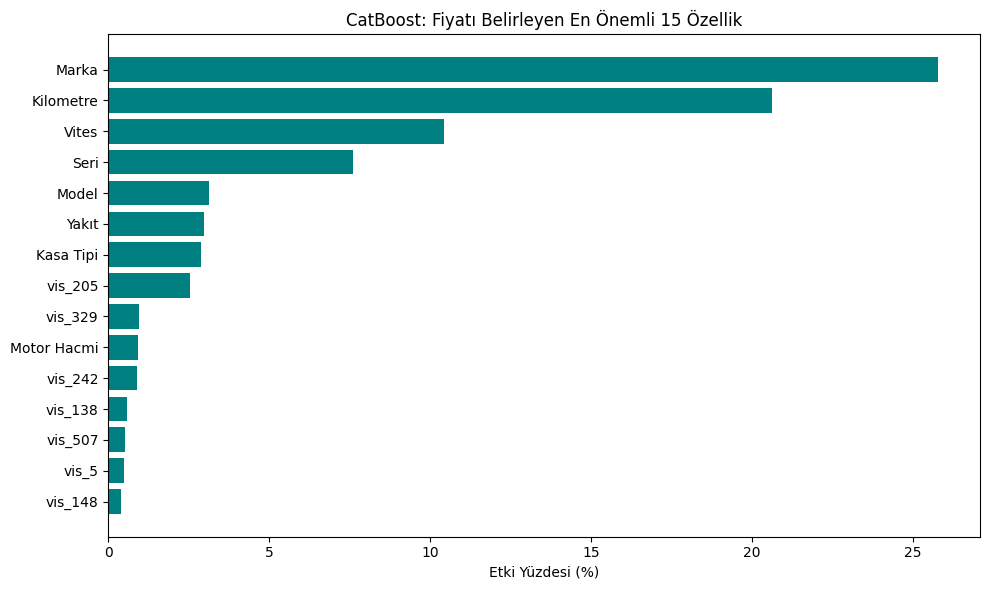

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor

# Eğitilmiş modeli yükle
model = CatBoostRegressor()
model.load_model("/content/catboost_fiyat_modeli.cbm")

# Özellik önemlerini al
feature_importances = model.get_feature_importance()

# ÇÖZÜM BURADA: Sütun isimlerini doğrudan modelin hafızasından çekiyoruz
feature_names = model.feature_names_

# Tabloyu oluştur ve en önemli 15 özelliği sırala
importance_df = pd.DataFrame({'Özellik': feature_names, 'Önem (%)': feature_importances})
importance_df = importance_df.sort_values(by='Önem (%)', ascending=False).head(15)

# Grafiği çizdir
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Özellik'][::-1], importance_df['Önem (%)'][::-1], color='teal')
plt.title('CatBoost: Fiyatı Belirleyen En Önemli 15 Özellik')
plt.xlabel('Etki Yüzdesi (%)')
plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from catboost import CatBoostRegressor
import warnings
warnings.filterwarnings('ignore')

CSV_PATH = "/content/araba_fiyat_tahmin_veriseti.csv"
FEATURES_NPY_PATH = "/content/gorsel_ozellikler.npy"
MODEL_SAVE_PATH = "/content/catboost_log_modeli.cbm"

def veriyi_hazirla():
    df = pd.read_csv(CSV_PATH)
    X_vision = np.load(FEATURES_NPY_PATH)

    if df['Fiyat'].dtype == object:
        df['Fiyat'] = df['Fiyat'].astype(str).str.replace(' TL', '', regex=False).str.replace('.', '', regex=False)
        df['Fiyat'] = pd.to_numeric(df['Fiyat'], errors='coerce')

    if df['Kilometre'].dtype == object:
        df['Kilometre'] = df['Kilometre'].astype(str).str.replace(' km', '', regex=False).str.replace('.', '', regex=False)
        df['Kilometre'] = pd.to_numeric(df['Kilometre'], errors='coerce')

    df = df.dropna(subset=['Fiyat', 'Kilometre'])

    # Aykırı Değer Temizliği
    q_low = df['Fiyat'].quantile(0.01)
    q_hi  = df['Fiyat'].quantile(0.99)
    df = df[(df['Fiyat'] > q_low) & (df['Fiyat'] < q_hi)]

    valid_indices = df.index
    X_vision_valid = X_vision[valid_indices]

    kategorik_sutunlar = ['Marka', 'Seri', 'Model', 'Kasa Tipi', 'Yakıt', 'Vites', 'Motor Hacmi']
    df[kategorik_sutunlar] = df[kategorik_sutunlar].fillna('Bilinmiyor').astype(str)

    X_tabular = df[['Kilometre'] + kategorik_sutunlar]
    y = df['Fiyat'].values

    vision_df = pd.DataFrame(X_vision_valid, columns=[f"vis_{i}" for i in range(512)], index=df.index)
    X_final = pd.concat([X_tabular, vision_df], axis=1)

    return X_final, y, kategorik_sutunlar

def main():
    X, y, cat_features = veriyi_hazirla()

    X_train, X_eval, y_train, y_eval = train_test_split(X, y, test_size=0.2, random_state=42)

    # ---------------------------------------------------------
    # SİHİRLİ DOKUNUŞ: Hedef değişkene (Fiyat) Logaritmik Dönüşüm
    # ---------------------------------------------------------
    y_train_log = np.log1p(y_train)
    y_eval_log = np.log1p(y_eval)

    print("\n==========================================")
    print("CatBoost Eğitimi Başlıyor (Log-Transform Aktif)")
    print("==========================================")

    model = CatBoostRegressor(
        iterations=2000,          # Öğrenme süresini biraz artırdık
        learning_rate=0.05,       # Daha hassas öğrenmesi için hızı biraz düşürdük
        depth=6,
        eval_metric='RMSE',
        random_seed=42,
        task_type='GPU',
        early_stopping_rounds=150 # Sabır süresini uzattık
    )

    # Modeli logaritmik verilerle eğitiyoruz
    model.fit(
        X_train, y_train_log,
        cat_features=cat_features,
        eval_set=(X_eval, y_eval_log),
        verbose=200
    )

    model.save_model(MODEL_SAVE_PATH)

    # ---------------------------------------------------------
    # TEST: Tahminleri tekrar normal TL cinsine çevirme (Ters Log)
    # ---------------------------------------------------------
    y_pred_log = model.predict(X_eval)
    y_pred = np.expm1(y_pred_log) # Logaritmayı geri al (Üstel fonksiyon)

    mae = mean_absolute_error(y_eval, y_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred))
    r2 = r2_score(y_eval, y_pred)

    print("\n" + "="*50)
    print("LOG-TRANSFORM SONRASI PERFORMANS RAPORU")
    print("="*50)
    print(f"R-Kare Skoru (R2)   : {r2:.4f}")
    print(f"Ortalama Hata (MAE) : {mae:,.2f} TL")
    print(f"Karekök Hata (RMSE) : {rmse:,.2f} TL")
    print("="*50)

if __name__ == "__main__":
    main()


CatBoost Eğitimi Başlıyor (Log-Transform Aktif)
0:	learn: 0.5834601	test: 0.5904003	best: 0.5904003 (0)	total: 267ms	remaining: 8m 52s
200:	learn: 0.1943524	test: 0.2088438	best: 0.2088438 (200)	total: 11.3s	remaining: 1m 40s
400:	learn: 0.1733417	test: 0.2022642	best: 0.2022642 (400)	total: 21.4s	remaining: 1m 25s
600:	learn: 0.1587374	test: 0.1996597	best: 0.1996361 (593)	total: 30.9s	remaining: 1m 11s
800:	learn: 0.1476120	test: 0.1985115	best: 0.1985115 (800)	total: 39.9s	remaining: 59.7s
1000:	learn: 0.1383865	test: 0.1973704	best: 0.1973592 (996)	total: 49.9s	remaining: 49.8s
1200:	learn: 0.1313554	test: 0.1971622	best: 0.1970906 (1179)	total: 58.9s	remaining: 39.2s
1400:	learn: 0.1254670	test: 0.1966622	best: 0.1966400 (1390)	total: 1m 7s	remaining: 28.9s
1600:	learn: 0.1205355	test: 0.1963570	best: 0.1963490 (1558)	total: 1m 17s	remaining: 19.3s
1800:	learn: 0.1158338	test: 0.1960260	best: 0.1960121 (1798)	total: 1m 26s	remaining: 9.57s
1999:	learn: 0.1113333	test: 0.1957073	b

In [ ]:
import pandas as pd
import numpy as np
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split

# 1. Modeli Yükle
model = CatBoostRegressor()
model.load_model("/content/catboost_log_modeli.cbm")

# 2. Veriyi ve İndeksleri Aynı Şekilde Hazırla (Eşleşme bozulmasın diye)
df = pd.read_csv("/content/araba_fiyat_tahmin_veriseti.csv")

# Temel temizlik (Aynı adımlar)
df['Fiyat'] = df['Fiyat'].astype(str).str.replace(' TL', '', regex=False).str.replace('.', '', regex=False)
df['Fiyat'] = pd.to_numeric(df['Fiyat'], errors='coerce')
df['Kilometre'] = df['Kilometre'].astype(str).str.replace(' km', '', regex=False).str.replace('.', '', regex=False)
df['Kilometre'] = pd.to_numeric(df['Kilometre'], errors='coerce')
df = df.dropna(subset=['Fiyat', 'Kilometre'])

q_low = df['Fiyat'].quantile(0.01)
q_hi  = df['Fiyat'].quantile(0.99)
df_filtered = df[(df['Fiyat'] > q_low) & (df['Fiyat'] < q_hi)].copy()

X_vision = np.load("/content/gorsel_ozellikler.npy")
valid_indices = df_filtered.index
X_vision_valid = X_vision[valid_indices]

kategorik_sutunlar = ['Marka', 'Seri', 'Model', 'Kasa Tipi', 'Yakıt', 'Vites', 'Motor Hacmi']
df_filtered[kategorik_sutunlar] = df_filtered[kategorik_sutunlar].fillna('Bilinmiyor').astype(str)

X_tabular = df_filtered[['Kilometre'] + kategorik_sutunlar]
y = df_filtered['Fiyat'].values

vision_df = pd.DataFrame(X_vision_valid, columns=[f"vis_{i}" for i in range(512)], index=df_filtered.index)
X_final = pd.concat([X_tabular, vision_df], axis=1)

# Aynı seed (42) ile böldüğümüz için X_eval birebir aynı araçlara denk gelecek
X_train, X_eval, y_train, y_eval, indices_train, indices_eval = train_test_split(
    X_final, y, df_filtered.index, test_size=0.2, random_state=42
)

# 3. Tahminleri Yap ve Geri Çevir
y_pred_log = model.predict(X_eval)
y_pred = np.expm1(y_pred_log) # Logaritmayı iptal et

# 4. Hata Tablosunu Oluştur
hata_df = df_filtered.loc[indices_eval].copy()
hata_df['Tahmin_Fiyat'] = y_pred
hata_df['Gercek_Fiyat'] = y_eval
hata_df['Hata_TL'] = np.abs(hata_df['Gercek_Fiyat'] - hata_df['Tahmin_Fiyat'])
hata_df['Hata_Orani_%'] = (hata_df['Hata_TL'] / hata_df['Gercek_Fiyat']) * 100

# Sadece incelemek istediğimiz sütunları seçip Hata_TL'ye göre azalan şekilde sıralayalım
sonuc_tablosu = hata_df[['İlan No', 'Marka', 'Seri', 'Yıl', 'Kilometre', 'Gercek_Fiyat', 'Tahmin_Fiyat', 'Hata_TL', 'Hata_Orani_%', 'Görsel Klasör Yolu']]
en_kötü_10 = sonuc_tablosu.sort_values(by='Hata_TL', ascending=False).head(10)

# Ekrana daha okunaklı basmak için formatlama
pd.options.display.float_format = '{:,.0f}'.format
print("\n=== MODELİN EN ÇOK YANILDIĞI 10 ARAÇ ===")
display(en_kötü_10[['Marka', 'Seri', 'Yıl', 'Kilometre', 'Gercek_Fiyat', 'Tahmin_Fiyat', 'Hata_TL', 'Hata_Orani_%']])


=== MODELİN EN ÇOK YANILDIĞI 10 ARAÇ ===


,Marka,Seri,Yıl,Kilometre,Gercek_Fiyat,Tahmin_Fiyat,Hata_TL,Hata_Orani_%
4586,Mercedes - Benz,S,2014,"256,000","3,990,000","2,009,802","1,980,198",50
4147,Mercedes - Benz,E,2018,"351,000","3,450,000","1,685,879","1,764,121",51
4372,Mercedes - Benz,C,2022,"75,000","3,850,000","2,202,872","1,647,128",43
4283,Mercedes - Benz,C,2023,"40,500","4,095,000","2,581,972","1,513,028",37
1071,BMW,4 Serisi,2022,"49,000","3,989,000","2,645,744","1,343,256",34
4796,Mercedes - Benz,C,2021,"99,500","3,695,000","2,375,876","1,319,124",36
4124,Mercedes - Benz,E,2018,"115,000","3,450,000","2,307,335","1,142,665",33
999,BMW,5 Serisi,2018,"168,000","3,250,000","2,147,564","1,102,436",34
1095,BMW,7 Serisi,2009,"230,000","2,500,000","1,422,934","1,077,066",43
4627,Mercedes - Benz,E,2020,"119,000","4,000,000","2,935,572","1,064,428",27


In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from catboost import CatBoostRegressor
import warnings
warnings.filterwarnings('ignore')

CSV_PATH = "/content/araba_fiyat_tahmin_veriseti.csv"
FEATURES_NPY_PATH = "/content/gorsel_ozellikler.npy"
MODEL_SAVE_PATH = "/content/catboost_premium_modeli.cbm"

def premium_veriyi_hazirla():
    df = pd.read_csv(CSV_PATH)
    X_vision = np.load(FEATURES_NPY_PATH)

    # 1. Temel Temizlik
    if df['Fiyat'].dtype == object:
        df['Fiyat'] = df['Fiyat'].astype(str).str.replace(' TL', '', regex=False).str.replace('.', '', regex=False)
        df['Fiyat'] = pd.to_numeric(df['Fiyat'], errors='coerce')

    if df['Kilometre'].dtype == object:
        df['Kilometre'] = df['Kilometre'].astype(str).str.replace(' km', '', regex=False).str.replace('.', '', regex=False)
        df['Kilometre'] = pd.to_numeric(df['Kilometre'], errors='coerce')

    df = df.dropna(subset=['Fiyat', 'Kilometre'])

    # ---------------------------------------------------------
    # STRATEJİK ADIM: Sadece Premium Markaları Filtrele
    # ---------------------------------------------------------
    # str.contains ile içinde bu kelimeler geçen markaları alıyoruz (Örn: "Mercedes - Benz")
    premium_markalar = ['Mercedes', 'BMW', 'Audi', 'Porsche', 'Land Rover']
    df_premium = df[df['Marka'].str.contains('|'.join(premium_markalar), case=False, na=False)].copy()

    print(f"[BİLGİ] Toplam İlan İçerisinden Filtrelenen Premium Araç Sayısı: {len(df_premium)}")

    # 2. Premium Araçlar İçin Kendi İçinde Aykırı Değer Temizliği
    q_low = df_premium['Fiyat'].quantile(0.02) # Sınırları biraz daha daraltıyoruz
    q_hi  = df_premium['Fiyat'].quantile(0.98)
    df_premium = df_premium[(df_premium['Fiyat'] > q_low) & (df_premium['Fiyat'] < q_hi)]

    # 3. Görsel Matrisi Filtrelenmiş İndekslere Göre Eşleştir
    valid_indices = df_premium.index
    X_vision_valid = X_vision[valid_indices]

    # 4. Kategorik Sütunlar ve Birleştirme
    kategorik_sutunlar = ['Marka', 'Seri', 'Model', 'Kasa Tipi', 'Yakıt', 'Vites', 'Motor Hacmi']
    df_premium[kategorik_sutunlar] = df_premium[kategorik_sutunlar].fillna('Bilinmiyor').astype(str)

    X_tabular = df_premium[['Kilometre'] + kategorik_sutunlar]
    y = df_premium['Fiyat'].values

    vision_df = pd.DataFrame(X_vision_valid, columns=[f"vis_{i}" for i in range(512)], index=df_premium.index)
    X_final = pd.concat([X_tabular, vision_df], axis=1)

    return X_final, y, kategorik_sutunlar

def main():
    X, y, cat_features = premium_veriyi_hazirla()

    # Veri setimiz küçüldüğü için Test oranını %15'e çekiyoruz
    X_train, X_eval, y_train, y_eval = train_test_split(X, y, test_size=0.15, random_state=42)

    # Logaritmik Dönüşüm (Premium araçlardaki devasa fiyat farklarını dizginlemek için)
    y_train_log = np.log1p(y_train)
    y_eval_log = np.log1p(y_eval)

    print("\n==========================================")
    print("Premium Segmente Özel CatBoost Eğitimi Başlıyor")
    print("==========================================")

    model = CatBoostRegressor(
        iterations=1500,
        learning_rate=0.06,
        depth=6,
        eval_metric='RMSE',
        random_seed=42,
        task_type='GPU',
        early_stopping_rounds=100
    )

    model.fit(
        X_train, y_train_log,
        cat_features=cat_features,
        eval_set=(X_eval, y_eval_log),
        verbose=100
    )

    model.save_model(MODEL_SAVE_PATH)

    # Tahminleri logaritmadan çıkartıp gerçek TL cinsine çevirme
    y_pred_log = model.predict(X_eval)
    y_pred = np.expm1(y_pred_log)

    mae = mean_absolute_error(y_eval, y_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred))
    r2 = r2_score(y_eval, y_pred)

    print("\n" + "="*50)
    print("PREMIUM MODEL PERFORMANS RAPORU")
    print("="*50)
    print(f"R-Kare Skoru (R2)   : {r2:.4f}")
    print(f"Ortalama Hata (MAE) : {mae:,.2f} TL")
    print(f"Karekök Hata (RMSE) : {rmse:,.2f} TL")
    print("="*50)

if __name__ == "__main__":
    main()

[BİLGİ] Toplam İlan İçerisinden Filtrelenen Premium Araç Sayısı: 985

Premium Segmente Özel CatBoost Eğitimi Başlıyor
0:	learn: 0.5750005	test: 0.5759698	best: 0.5759698 (0)	total: 112ms	remaining: 2m 48s
100:	learn: 0.2286958	test: 0.3137127	best: 0.3137127 (100)	total: 4.03s	remaining: 55.8s
200:	learn: 0.1853232	test: 0.3065189	best: 0.3064035 (199)	total: 7.67s	remaining: 49.5s
300:	learn: 0.1591565	test: 0.3042916	best: 0.3042230 (275)	total: 12.5s	remaining: 49.7s
400:	learn: 0.1427684	test: 0.3017586	best: 0.3014355 (392)	total: 16.9s	remaining: 46.4s
500:	learn: 0.1301357	test: 0.3008667	best: 0.3008593 (496)	total: 20.5s	remaining: 41s
600:	learn: 0.1197350	test: 0.2999801	best: 0.2993519 (569)	total: 24.1s	remaining: 36.1s
bestTest = 0.2993518616
bestIteration = 569
Shrink model to first 570 iterations.

PREMIUM MODEL PERFORMANS RAPORU
R-Kare Skoru (R2)   : 0.7084
Ortalama Hata (MAE) : 419,184.03 TL
Karekök Hata (RMSE) : 688,088.84 TL


In [ ]:
# ==========================================
# 1. İMPORTLAR
# ==========================================
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
from PIL import Image
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from catboost import CatBoostRegressor
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 2. HİPERPARAMETRELER
# ==========================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_SIZE = 224 # ViT-B/16 için standart boyut
BATCH_SIZE = 1
CSV_PATH = "/content/araba_fiyat_tahmin_veriseti.csv"
FEATURES_NPY_PATH = "/content/gorsel_ozellikler_vit.npy"
MODEL_SAVE_PATH = "/content/catboost_vit_log_modeli.cbm"

# ==========================================
# 3. DATASET LOADER
# ==========================================
class CarImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        folder = self.df.iloc[idx]['Görsel Klasör Yolu']
        images = []

        # B. GÖRSEL ÖNİŞLEME: Klasördeki 10 adet fotoğrafı bul ve oku
        if pd.notna(folder) and os.path.exists(folder):
            img_files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))][:10]
            for img_name in img_files:
                try:
                    img_path = os.path.join(folder, img_name)
                    img = Image.open(img_path).convert('RGB')
                    if self.transform:
                        img = self.transform(img)
                    images.append(img)
                except Exception:
                    pass

        # Eğer klasör boşsa, modele hata verdirmemek için siyah (sıfır) bir tensör dönüyoruz
        if len(images) == 0:
            dummy = torch.zeros(3, IMG_SIZE, IMG_SIZE)
            return torch.stack([dummy])

        return torch.stack(images)

# ==========================================
# 4. MODEL (A. KAFA KESME VE DONDURMA - ViT)
# ==========================================
def get_feature_extractor():
    print(f"[BİLGİ] Vision Transformer (ViT-B/16) Yükleniyor... (Cihaz: {DEVICE})")
    weights = models.ViT_B_16_Weights.DEFAULT
    model = models.vit_b_16(weights=weights)

    # Kafa Kesme: ViT'te sınıflandırma katmanı 'heads' olarak geçer. Etkisizleştiriyoruz.
    # Artık bize 768 boyutlu özellik vektörü verecek
    model.heads = nn.Identity()
    model.to(DEVICE)
    model.eval()

    # ViT'in kendi özel ön işleme (preprocess) standartlarını döndürüyoruz
    preprocess = weights.transforms()
    return model, preprocess

def tabular_veriyi_temizle(df):
    """
    CatBoost için Fiyat ve KM temizliği, aykırı değer kırpması ve kategorik sütun düzenlemesi.
    """
    df_clean = df.copy()

    if df_clean['Fiyat'].dtype == object:
        df_clean['Fiyat'] = df_clean['Fiyat'].astype(str).str.replace(' TL', '', regex=False).str.replace('.', '', regex=False)
        df_clean['Fiyat'] = pd.to_numeric(df_clean['Fiyat'], errors='coerce')

    if df_clean['Kilometre'].dtype == object:
        df_clean['Kilometre'] = df_clean['Kilometre'].astype(str).str.replace(' km', '', regex=False).str.replace('.', '', regex=False)
        df_clean['Kilometre'] = pd.to_numeric(df_clean['Kilometre'], errors='coerce')

    df_clean = df_clean.dropna(subset=['Fiyat', 'Kilometre'])

    # Aykırı Değer (Outlier) Temizliği (%1 alt ve üst)
    q_low = df_clean['Fiyat'].quantile(0.01)
    q_hi  = df_clean['Fiyat'].quantile(0.99)
    df_clean = df_clean[(df_clean['Fiyat'] > q_low) & (df_clean['Fiyat'] < q_hi)]

    # CatBoost One-Hot Encoding istemez. Kategorik sütunları string olarak bırakıyoruz.
    kategorik_sutunlar = ['Marka', 'Seri', 'Model', 'Kasa Tipi', 'Yakıt', 'Vites', 'Motor Hacmi']
    df_clean[kategorik_sutunlar] = df_clean[kategorik_sutunlar].fillna('Bilinmiyor').astype(str)

    return df_clean, kategorik_sutunlar

# ==========================================
# 8. MAIN
# ==========================================
def main():
    if not os.path.exists(CSV_PATH):
        print(f"HATA: {CSV_PATH} bulunamadı!")
        return

    df = pd.read_csv(CSV_PATH)

    # ViT modelini ve ona özel preprocess ayarlarını al
    model, vit_transform = get_feature_extractor()

    dataset = CarImageDataset(df, transform=vit_transform)
    dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)

    # ---------------------------------------------------------
    # GÖRSEL ÖZNİTELİK ÇIKARIMI (Eğer daha önce üretilmediyse)
    # ---------------------------------------------------------
    if not os.path.exists(FEATURES_NPY_PATH):
        all_features = []

        # ==========================================
        # 6. TQDM Bar Tanımlaması (B. Vektör Üretimi)
        # ==========================================
        print("\n[BİLGİ] ViT ile Fotoğraflardan Özellik Çıkarımı Başlıyor...")
        pbar = tqdm(dataloader, total=len(dataloader), desc="Görüntü İşleme (ViT)")

        with torch.no_grad():
            for images in pbar:
                images = images.squeeze(0).to(DEVICE)
                features = model(images) # Her fotoğraf için (10, 768)

                # C. 10 FOTOĞRAFI TEK ARAÇ KİMLİĞİNE DÖNÜŞTÜRME (MEAN POOLING)
                mean_feature = torch.mean(features, dim=0) # 10 vektörü toplayıp ortalama al -> (768,)
                all_features.append(mean_feature.cpu().numpy())

        pbar.close()
        X_vision = np.array(all_features)
        np.save(FEATURES_NPY_PATH, X_vision)
        print(f"\n[BİLGİ] ViT matrisi {FEATURES_NPY_PATH} olarak kaydedildi.")
    else:
        print(f"\n[BİLGİ] Hazır ViT özellikleri yüklendi: {FEATURES_NPY_PATH}")
        X_vision = np.load(FEATURES_NPY_PATH)

    # ==========================================
    # MULTI-MODAL VERİ BİRLEŞTİRME (FUSION)
    # ==========================================
    df_clean, cat_features = tabular_veriyi_temizle(df)

    y = df_clean['Fiyat'].values
    X_tabular = df_clean[['Kilometre'] + cat_features]

    # Temizleme sırasında atılan sorunlu satırların görsel vektörlerini de atıyoruz
    valid_indices = df_clean.index
    X_vision_valid = X_vision[valid_indices]

    # Tablo ve 768 Boyutlu ViT özelliklerini Pandas ile birleştiriyoruz
    vektor_boyutu = X_vision_valid.shape[1] # 768
    vision_df = pd.DataFrame(X_vision_valid, columns=[f"vis_{i}" for i in range(vektor_boyutu)], index=df_clean.index)
    X_final = pd.concat([X_tabular, vision_df], axis=1)

    print(f"[BİLGİ] Veriler Birleştirildi! Model eğitilecek toplam özellik (sütun) sayısı: {X_final.shape[1]}\n")

    X_train, X_eval, y_train, y_eval = train_test_split(X_final, y, test_size=0.2, random_state=42)

    # Logaritmik Dönüşüm
    y_train_log = np.log1p(y_train)
    y_eval_log = np.log1p(y_eval)

    # ==========================================
    # 5. TRAIN & 7. EVAL (CatBoost Fiyat Tahmin Eğitimi)
    # ==========================================
    print("==========================================")
    print("CatBoost Fiyat Tahmin Modeli Eğitimi Başlıyor (ViT + Log-Transform)")
    print("==========================================")

    # 9. Checkpoint (LOSS'a göre kontrol): early_stopping_rounds ile validasyon hatası düşmezse durur.
    cat_model = CatBoostRegressor(
        iterations=2000,
        learning_rate=0.05,
        depth=6,
        eval_metric='RMSE',
        random_seed=42,
        task_type='GPU',
        early_stopping_rounds=150
    )

    cat_model.fit(
        X_train, y_train_log,
        cat_features=cat_features,
        eval_set=(X_eval, y_eval_log),
        verbose=100
    )

    cat_model.save_model(MODEL_SAVE_PATH)
    print(f"\n[BAŞARILI] En düşük kayba (loss) sahip model kaydedildi: {MODEL_SAVE_PATH}")

    # ==========================================
    # 10. CLASSIFICATION (REGRESSION) REPORT
    # ==========================================
    print("\n" + "="*50)
    print("10. REGRESYON PERFORMANS RAPORU (TEST SONUÇLARI)")
    print("="*50)

    y_pred_log = cat_model.predict(X_eval)
    y_pred = np.expm1(y_pred_log) # Ters Log

    mae = mean_absolute_error(y_eval, y_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred))
    r2 = r2_score(y_eval, y_pred)

    print(f"R-Kare Skoru (R2)   : {r2:.4f}")
    print(f"Ortalama Hata (MAE) : {mae:,.2f} TL")
    print(f"Karekök Hata (RMSE) : {rmse:,.2f} TL")
    print("="*50)
    print("Proje hattı başarıyla tamamlandı!")

if __name__ == "__main__":
    main()

[BİLGİ] Vision Transformer (ViT-B/16) Yükleniyor... (Cihaz: cuda)
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 98.9MB/s]



[BİLGİ] ViT ile Fotoğraflardan Özellik Çıkarımı Başlıyor...


Görüntü İşleme (ViT): 100%|██████████| 7851/7851 [31:43<00:00,  4.12it/s]



[BİLGİ] ViT matrisi /content/gorsel_ozellikler_vit.npy olarak kaydedildi.
[BİLGİ] Veriler Birleştirildi! Model eğitilecek toplam özellik (sütun) sayısı: 776

CatBoost Fiyat Tahmin Modeli Eğitimi Başlıyor (ViT + Log-Transform)
0:	learn: 0.5832688	test: 0.5899481	best: 0.5899481 (0)	total: 65.9ms	remaining: 2m 11s
100:	learn: 0.2099691	test: 0.2189362	best: 0.2189362 (100)	total: 6.99s	remaining: 2m 11s
200:	learn: 0.1910773	test: 0.2044301	best: 0.2044301 (200)	total: 12.2s	remaining: 1m 49s
300:	learn: 0.1786396	test: 0.2004499	best: 0.2004446 (299)	total: 19.1s	remaining: 1m 48s
400:	learn: 0.1691740	test: 0.1982104	best: 0.1982012 (396)	total: 24.3s	remaining: 1m 36s
500:	learn: 0.1615443	test: 0.1968469	best: 0.1968469 (500)	total: 29.8s	remaining: 1m 29s
600:	learn: 0.1551002	test: 0.1960488	best: 0.1960488 (600)	total: 36s	remaining: 1m 23s
700:	learn: 0.1492724	test: 0.1947835	best: 0.1947833 (698)	total: 41.1s	remaining: 1m 16s
800:	learn: 0.1435964	test: 0.1940669	best: 0.1940

In [ ]:
import os
import torch
import torchvision.models as models
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# ---------------------------------------------------------
# 1. TEST EDİLECEK YENİ ARACIN BİLGİLERİ (Burası Değiştirilebilir)
# ---------------------------------------------------------
TEST_KLASOR_YOLU = "/content/dataset/Araba_Fiyat_Tahmin/fiat/ilan_24716572_veriseti"

yeni_arac_verileri = {
    'Marka': 'Fiat',
    'Seri': 'Albea',
    'Model': '1.3 Multijet Active',
    'Yıl': 2006,            # Modelimizin eğitiminde Yıl'ı kullanmadık (KM ve Seri üzerinden gidiyor)
    'Kilometre': 273800,
    'Kasa Tipi': 'Sedan',
    'Yakıt': 'Dizel',
    'Vites': 'Düz',
    'Motor Hacmi': '1.3 Multijet'
}
# Gerçek Fiyat (Referans): 290.000 TL

# ---------------------------------------------------------
# 2. MODELLERİ YÜKLEME VE TAHMİN (INFERENCE) FONKSİYONU
# ---------------------------------------------------------
def predict_price(arac_bilgileri, klasor_yolu):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("\n[1/3] Görüntü İşleme Motoru (ViT) Başlatılıyor...")

    # --- ViT Yükleme ve Özellik Çıkarma ---
    weights = models.ViT_B_16_Weights.DEFAULT
    vit_model = models.vit_b_16(weights=weights)
    vit_model.heads = torch.nn.Identity()
    vit_model.to(device).eval()
    preprocess = weights.transforms()

    images = [f for f in os.listdir(klasor_yolu) if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:10]

    if not images:
        print("HATA: Klasörde fotoğraf bulunamadı!")
        return

    vectors = []
    with torch.no_grad():
        for img_name in images:
            img_path = os.path.join(klasor_yolu, img_name)
            try:
                img = Image.open(img_path).convert('RGB')
                input_tensor = preprocess(img).unsqueeze(0).to(device)
                feature_vector = vit_model(input_tensor)
                vectors.append(feature_vector.cpu().numpy().flatten())
            except Exception as e:
                pass

    gorsel_vektor = np.mean(vectors, axis=0).reshape(1, -1)
    print(f"[2/3] Fotoğraflar başarıyla işlendi ve {gorsel_vektor.shape[1]} boyutlu öznitelik çıkarıldı.")

    # --- Veri Hazırlama (Tablo + ViT) ---
    # Sözlüğü tek satırlık bir Pandas DataFrame'e çeviriyoruz
    df_tabular = pd.DataFrame([arac_bilgileri])

    # Eğitim sırasında kullandığımız sütun sırasını birebir korumalıyız
    beklenen_kategorik_sutunlar = ['Marka', 'Seri', 'Model', 'Kasa Tipi', 'Yakıt', 'Vites', 'Motor Hacmi']
    df_tabular[beklenen_kategorik_sutunlar] = df_tabular[beklenen_kategorik_sutunlar].fillna('Bilinmiyor').astype(str)

    # ViT Vektörlerini DataFrame sütunları yapıyoruz
    df_vision = pd.DataFrame(gorsel_vektor, columns=[f"vis_{i}" for i in range(768)])

    # Tüm veriyi birleştir
    X_yeni = pd.concat([df_tabular[['Kilometre'] + beklenen_kategorik_sutunlar], df_vision], axis=1)

    # --- CatBoost Fiyat Tahmini ---
    print("[3/3] CatBoost Fiyat Değerleme Modeline Bağlanılıyor...")
    model_yolu = "/content/catboost_vit_log_modeli.cbm"

    if not os.path.exists(model_yolu):
        print(f"HATA: CatBoost model dosyası bulunamadı! ({model_yolu})")
        return

    cb_model = CatBoostRegressor()
    cb_model.load_model(model_yolu)

    # Tahmin yap ve Logaritmayı tersine çevir
    tahmin_log = cb_model.predict(X_yeni)[0]
    tahmin_tl = np.expm1(tahmin_log)

    print("\n" + "="*50)
    print("🚗 AUTO VALUATE AI+ : TAHMİN SONUCU")
    print("="*50)
    print(f"Araç: {arac_bilgileri['Marka']} {arac_bilgileri['Seri']} ({arac_bilgileri['Kilometre']:,} km)")
    print(f"Yapay Zeka Tahmini Fiyat: {tahmin_tl:,.0f} TL")
    print("="*50)

# Kodu Çalıştır
if __name__ == "__main__":
    predict_price(yeni_arac_verileri, TEST_KLASOR_YOLU)


[1/3] Görüntü İşleme Motoru (ViT) Başlatılıyor...
[2/3] Fotoğraflar başarıyla işlendi ve 768 boyutlu öznitelik çıkarıldı.
[3/3] CatBoost Fiyat Değerleme Modeline Bağlanılıyor...

🚗 AUTO VALUATE AI+ : TAHMİN SONUCU
Araç: Fiat Albea (273,800 km)
Yapay Zeka Tahmini Fiyat: 298,659 TL


In [ ]:
from google.colab import files

# En son eğittiğimiz ve kaydettiğimiz model dosyasını indir
files.download('/content/catboost_vit_log_modeli.cbm')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('/content/araba_fiyat_tahmin_veriseti.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>